# Notebook 01 — Data Audit, Metadata & Quality Control
## Parkinson metabolic transcriptomics project

**Datasets**
- **GSE136666** — bulk RNA-seq, substantia nigra and putamen.
- **GSE184950** — single-nucleus RNA-seq (snRNA-seq), substantia nigra. In this notebook we audit **sample/donor metadata only**; cell-level matrices are reserved for Notebook 06.

### Scientific questions
1. What is the exact structure of each dataset?
2. Are sample identifiers consistent between counts and metadata?
3. How balanced are disease, tissue, sex, age and donor variables?
4. Are there obvious sequencing-depth or count-distribution anomalies in GSE136666?
5. Which files should be exported as validated inputs for Notebook 02?

### Methodological rules
- We **do not merge** GSE136666 and GSE184950 expression matrices.
- GSE136666 is the **bulk discovery cohort**.
- GSE184950 will be an **independent cell-resolution validation cohort**.
- Repeated nuclei/cells from one donor are **not independent biological replicates**.
- Original files are never modified.

In [1]:
# 0. Environment and imports
from pathlib import Path
import csv
import json
import re
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
pandas: 2.2.3
numpy: 2.3.5


In [2]:
# 1. Project folders
PROJECT_ROOT = Path.cwd()

SEARCH_ROOTS = [
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    PROJECT_ROOT / "data",
    PROJECT_ROOT.parent / "data",
    Path("/mnt/data"),
]

RESULTS_DIR = PROJECT_ROOT / "results" / "QC"
FIGURES_DIR = PROJECT_ROOT / "figures" / "QC"
EXPORT_DIR = PROJECT_ROOT / "data" / "processed" / "notebook01"

for d in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT.resolve())
print("RESULTS_DIR:", RESULTS_DIR.resolve())
print("FIGURES_DIR:", FIGURES_DIR.resolve())
print("EXPORT_DIR:", EXPORT_DIR.resolve())

PROJECT_ROOT: /mnt/data
RESULTS_DIR: /mnt/data/results/QC
FIGURES_DIR: /mnt/data/figures/QC
EXPORT_DIR: /mnt/data/data/processed/notebook01


In [3]:
# 2. Robust file discovery
def find_file(patterns, roots=SEARCH_ROOTS):
    if isinstance(patterns, str):
        patterns = [patterns]
    matches = []
    for root in roots:
        if not root.exists():
            continue
        for pattern in patterns:
            matches.extend(root.rglob(pattern))
    matches = sorted(set(p.resolve() for p in matches if p.is_file()))
    return matches[0] if matches else None

GSE136666_COUNTS = find_file([
    "GSE136666_raw_counts_GRCh38.p13_NCBI*.tsv",
    "*GSE136666*raw_counts*.tsv",
])

GSE136666_META = find_file([
    "GSE136666_series_matrix*.txt",
    "*GSE136666*series_matrix*.txt",
])

GSE184950_META = find_file([
    "GSE184950_series_matrix*.txt",
    "*GSE184950*series_matrix*.txt",
])

files_found = {
    "GSE136666_counts": str(GSE136666_COUNTS) if GSE136666_COUNTS else None,
    "GSE136666_metadata": str(GSE136666_META) if GSE136666_META else None,
    "GSE184950_metadata": str(GSE184950_META) if GSE184950_META else None,
}
display(pd.DataFrame(files_found.items(), columns=["resource", "path"]))

assert GSE136666_COUNTS is not None, "GSE136666 raw-count TSV was not found."
assert GSE136666_META is not None, "GSE136666 series_matrix file was not found."
assert GSE184950_META is not None, "GSE184950 series_matrix file was not found."

,resource,path
0,GSE136666_counts,/mnt/data/GSE136666_raw_counts_GRCh38.p13_NCBI...
1,GSE136666_metadata,/mnt/data/GSE136666_series_matrix(1).txt
2,GSE184950_metadata,/mnt/data/GSE184950_series_matrix.txt


## 3. GEO series-matrix parser

GEO stores sample metadata in rows such as `!Sample_title`, `!Sample_geo_accession`, and repeated `!Sample_characteristics_ch1` rows.  
The function below converts those rows into a clean **sample × variable** dataframe without hard-coding sample order.

In [4]:
def parse_geo_series_matrix(path):
    # Parse sample-level metadata from a GEO series_matrix text file.
    raw_fields = {}
    characteristic_rows = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.startswith("!"):
                continue

            parts = next(csv.reader([line], delimiter="\t", quotechar='"'))
            key = parts[0]
            values = parts[1:]

            if key == "!Sample_characteristics_ch1":
                characteristic_rows.append(values)
            else:
                raw_fields.setdefault(key, []).append(values)

    for key in ["!Sample_title", "!Sample_geo_accession"]:
        if key not in raw_fields:
            raise ValueError(f"Required GEO field missing: {key}")

    titles = raw_fields["!Sample_title"][0]
    accessions = raw_fields["!Sample_geo_accession"][0]

    if len(titles) != len(accessions):
        raise ValueError("Sample-title and GEO-accession counts differ.")

    metadata = pd.DataFrame({
        "sample_title": titles,
        "geo_accession": accessions,
    })

    if "!Sample_source_name_ch1" in raw_fields:
        source = raw_fields["!Sample_source_name_ch1"][0]
        if len(source) == len(metadata):
            metadata["source_name"] = source

    for values in characteristic_rows:
        if len(values) != len(metadata):
            continue

        prefixes = []
        parsed_values = []

        for value in values:
            if ":" in value:
                k, v = value.split(":", 1)
                prefixes.append(k.strip().lower())
                parsed_values.append(v.strip())
            else:
                prefixes.append(None)
                parsed_values.append(value.strip())

        valid_prefixes = [p for p in prefixes if p is not None]
        if valid_prefixes and len(set(valid_prefixes)) == 1:
            col = valid_prefixes[0]
            col = re.sub(r"[^a-z0-9]+", "_", col).strip("_")
            metadata[col] = parsed_values

    return metadata, raw_fields

# Part A — GSE136666 bulk RNA-seq

In [5]:
# 4. Load GSE136666 raw counts
bulk_counts = pd.read_csv(GSE136666_COUNTS, sep="\t")

print("Shape (genes × [GeneID + samples]):", bulk_counts.shape)
display(bulk_counts.head())

assert "GeneID" in bulk_counts.columns, "Expected GeneID column was not found."

sample_columns = [c for c in bulk_counts.columns if c != "GeneID"]
print("Number of genes:", len(bulk_counts))
print("Number of sample columns:", len(sample_columns))
print("First sample IDs:", sample_columns[:5])

Shape (genes × [GeneID + samples]): (39376, 17)


,GeneID,GSM4054763,GSM4054764,GSM4054765,GSM4054766,GSM4054767,GSM4054768,GSM4054769,GSM4054770,GSM4054771,GSM4054772,GSM4054773,GSM4054774,GSM4054775,GSM4054776,GSM4054777,GSM4054778
0,100287102,5,11,17,13,5,27,23,20,8,14,10,8,9,15,10,11
1,653635,782,612,783,1129,503,953,644,773,805,676,678,897,556,553,780,762
2,102466751,26,18,31,51,24,44,34,33,32,26,25,34,22,19,38,43
3,107985730,2,3,2,4,2,5,2,5,3,1,4,5,3,1,3,3
4,100302278,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,2


Number of genes: 39376
Number of sample columns: 16
First sample IDs: ['GSM4054763', 'GSM4054764', 'GSM4054765', 'GSM4054766', 'GSM4054767']


In [6]:
# 5. Integrity checks for bulk counts
bulk_integrity = {
    "n_genes": int(bulk_counts.shape[0]),
    "n_samples": int(len(sample_columns)),
    "geneid_missing": int(bulk_counts["GeneID"].isna().sum()),
    "geneid_duplicates": int(bulk_counts["GeneID"].duplicated().sum()),
    "count_missing_values": int(bulk_counts[sample_columns].isna().sum().sum()),
    "all_counts_numeric": bool(all(pd.api.types.is_numeric_dtype(bulk_counts[c]) for c in sample_columns)),
    "all_counts_nonnegative": bool((bulk_counts[sample_columns] >= 0).all().all()),
    "all_counts_integer_valued": bool(
        np.allclose(
            bulk_counts[sample_columns].to_numpy(dtype=float),
            np.round(bulk_counts[sample_columns].to_numpy(dtype=float))
        )
    ),
}

display(pd.Series(bulk_integrity, name="value"))

assert bulk_integrity["geneid_missing"] == 0
assert bulk_integrity["geneid_duplicates"] == 0
assert bulk_integrity["count_missing_values"] == 0
assert bulk_integrity["all_counts_numeric"]
assert bulk_integrity["all_counts_nonnegative"]
assert bulk_integrity["all_counts_integer_valued"]

n_genes                      39376
n_samples                       16
geneid_missing                   0
geneid_duplicates                0
count_missing_values             0
all_counts_numeric            True
all_counts_nonnegative        True
all_counts_integer_valued     True
Name: value, dtype: object

In [7]:
# 6. Parse and clean GSE136666 metadata
meta136, raw136 = parse_geo_series_matrix(GSE136666_META)

if "gender" in meta136:
    meta136["sex"] = meta136["gender"].str.upper().replace({"F": "Female", "M": "Male"})

if "disease_state" in meta136:
    meta136["disease"] = meta136["disease_state"].replace({
        "Control": "Control",
        "Parkinson’s disease": "Parkinson",
        "Parkinson's disease": "Parkinson",
    })

if "tissue" in meta136:
    meta136["tissue_clean"] = (
        meta136["tissue"]
        .str.replace("Substantia nigra", "Substantia_nigra", regex=False)
        .str.replace("Putamen", "Putamen", regex=False)
    )

display(meta136)
print("\nDisease counts:")
display(meta136["disease"].value_counts(dropna=False))
print("\nTissue × disease:")
display(pd.crosstab(meta136["tissue_clean"], meta136["disease"]))
print("\nSex × disease:")
display(pd.crosstab(meta136["sex"], meta136["disease"]))

,sample_title,geo_accession,source_name,gender,disease_state,tissue,sex,disease,tissue_clean
0,SN_C_1,GSM4054763,Substantia nigra,f,Control,Substantia nigra,Female,Control,Substantia_nigra
1,SN_C_2,GSM4054764,Substantia nigra,f,Control,Substantia nigra,Female,Control,Substantia_nigra
2,SN_C_3,GSM4054765,Substantia nigra,m,Control,Substantia nigra,Male,Control,Substantia_nigra
3,SN_C_4,GSM4054766,Substantia nigra,m,Control,Substantia nigra,Male,Control,Substantia_nigra
4,SN_C_5,GSM4054767,Substantia nigra,m,Control,Substantia nigra,Male,Control,Substantia_nigra
5,SN_PD_1,GSM4054768,Substantia nigra,f,Parkinson’s disease,Substantia nigra,Female,Parkinson,Substantia_nigra
6,SN_PD_2,GSM4054769,Substantia nigra,f,Parkinson’s disease,Substantia nigra,Female,Parkinson,Substantia_nigra
7,SN_PD_3,GSM4054770,Substantia nigra,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra
8,SN_PD_4,GSM4054771,Substantia nigra,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra
9,SN_PD_5,GSM4054772,Substantia nigra,m,Parkinson’s disease,Substantia nigra,Male,Parkinson,Substantia_nigra



Disease counts:


disease
Control      8
Parkinson    8
Name: count, dtype: int64


Tissue × disease:


disease,Control,Parkinson
tissue_clean,,
Putamen,3,3
Substantia_nigra,5,5



Sex × disease:


disease,Control,Parkinson
sex,,
Female,3,3
Male,5,5


In [8]:
# 7. Verify exact sample alignment between raw counts and GEO metadata
counts_ids = set(sample_columns)
metadata_ids = set(meta136["geo_accession"])

alignment_summary = {
    "count_columns": len(counts_ids),
    "metadata_samples": len(metadata_ids),
    "in_counts_not_metadata": sorted(counts_ids - metadata_ids),
    "in_metadata_not_counts": sorted(metadata_ids - counts_ids),
    "exact_set_match": counts_ids == metadata_ids,
}
display(pd.Series(alignment_summary, name="value"))

assert counts_ids == metadata_ids, "Counts and metadata GEO sample IDs do not match."

meta136 = (
    meta136
    .set_index("geo_accession")
    .loc[sample_columns]
    .reset_index()
)

assert meta136["geo_accession"].tolist() == sample_columns
print("✓ Metadata order exactly matches count-matrix columns.")

count_columns               16
metadata_samples            16
in_counts_not_metadata      []
in_metadata_not_counts      []
exact_set_match           True
Name: value, dtype: object

✓ Metadata order exactly matches count-matrix columns.


In [9]:
# 8. Bulk sequencing-depth QC
count_matrix = bulk_counts.set_index("GeneID")

library_size = count_matrix.sum(axis=0)
detected_gt0 = (count_matrix > 0).sum(axis=0)
detected_ge10 = (count_matrix >= 10).sum(axis=0)

bulk_qc = pd.DataFrame({
    "geo_accession": sample_columns,
    "library_size": library_size.loc[sample_columns].values,
    "detected_genes_gt0": detected_gt0.loc[sample_columns].values,
    "detected_genes_ge10": detected_ge10.loc[sample_columns].values,
}).merge(
    meta136[["geo_accession", "sample_title", "tissue_clean", "disease", "sex"]],
    on="geo_accession",
    how="left",
)

display(bulk_qc)
print("\nLibrary-size summary:")
display(bulk_qc["library_size"].describe())

,geo_accession,library_size,detected_genes_gt0,detected_genes_ge10,sample_title,tissue_clean,disease,sex
0,GSM4054763,35180013,30231,22002,SN_C_1,Substantia_nigra,Control,Female
1,GSM4054764,24892521,28580,20301,SN_C_2,Substantia_nigra,Control,Female
2,GSM4054765,26440540,29506,21188,SN_C_3,Substantia_nigra,Control,Male
3,GSM4054766,40476935,30651,22471,SN_C_4,Substantia_nigra,Control,Male
4,GSM4054767,20159733,28703,20317,SN_C_5,Substantia_nigra,Control,Male
5,GSM4054768,33658164,29889,21869,SN_PD_1,Substantia_nigra,Parkinson,Female
6,GSM4054769,22395839,27854,19743,SN_PD_2,Substantia_nigra,Parkinson,Female
7,GSM4054770,27974207,29529,21337,SN_PD_3,Substantia_nigra,Parkinson,Male
8,GSM4054771,34424341,30109,21870,SN_PD_4,Substantia_nigra,Parkinson,Male
9,GSM4054772,33788470,29992,21739,SN_PD_5,Substantia_nigra,Parkinson,Male



Library-size summary:


count    1.600000e+01
mean     2.999848e+07
std      6.436955e+06
min      1.921691e+07
25%      2.574115e+07
50%      3.079508e+07
75%      3.461326e+07
max      4.047694e+07
Name: library_size, dtype: float64

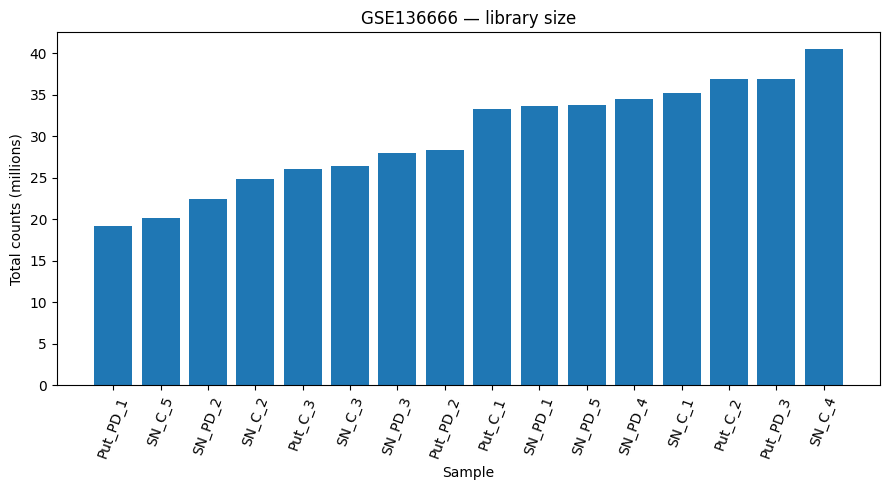

In [10]:
# 9. Figure — library size
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = bulk_qc.sort_values("library_size")
ax.bar(plot_df["sample_title"], plot_df["library_size"] / 1e6)
ax.set_ylabel("Total counts (millions)")
ax.set_xlabel("Sample")
ax.set_title("GSE136666 — library size")
ax.tick_params(axis="x", rotation=70)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE136666_library_size.png", dpi=300, bbox_inches="tight")
plt.show()

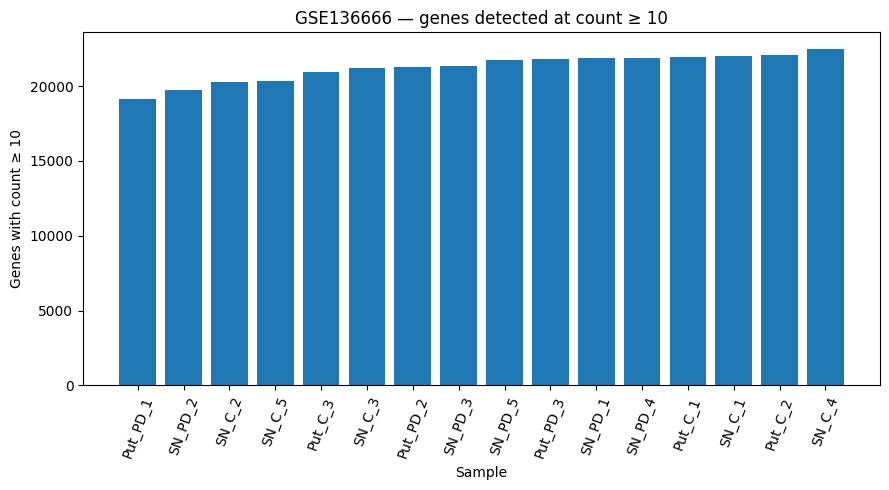

In [11]:
# 10. Figure — detected genes per sample
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = bulk_qc.sort_values("detected_genes_ge10")
ax.bar(plot_df["sample_title"], plot_df["detected_genes_ge10"])
ax.set_ylabel("Genes with count ≥ 10")
ax.set_xlabel("Sample")
ax.set_title("GSE136666 — genes detected at count ≥ 10")
ax.tick_params(axis="x", rotation=70)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE136666_detected_genes_ge10.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# 11. Global count-distribution QC
# log1p is used ONLY for visualization/QC, not as differential-expression input.
log_counts = np.log1p(count_matrix)

distribution_qc = pd.DataFrame({
    "geo_accession": sample_columns,
    "median_log1p_count": log_counts.median(axis=0).loc[sample_columns].values,
    "q75_log1p_count": log_counts.quantile(0.75, axis=0).loc[sample_columns].values,
    "q90_log1p_count": log_counts.quantile(0.90, axis=0).loc[sample_columns].values,
}).merge(
    meta136[["geo_accession", "sample_title", "tissue_clean", "disease"]],
    on="geo_accession",
    how="left"
)

display(distribution_qc)

,geo_accession,median_log1p_count,q75_log1p_count,q90_log1p_count,sample_title,tissue_clean,disease
0,GSM4054763,3.091042,6.320768,7.565275,SN_C_1,Substantia_nigra,Control
1,GSM4054764,2.564949,5.786897,7.061763,SN_C_2,Substantia_nigra,Control
2,GSM4054765,2.833213,5.913503,7.169735,SN_C_3,Substantia_nigra,Control
3,GSM4054766,3.258097,6.448889,7.663173,SN_C_4,Substantia_nigra,Control
4,GSM4054767,2.564949,5.669881,6.927558,SN_C_5,Substantia_nigra,Control
5,GSM4054768,3.044522,6.261492,7.532356,SN_PD_1,Substantia_nigra,Parkinson
6,GSM4054769,2.397895,5.590987,6.870053,SN_PD_2,Substantia_nigra,Parkinson
7,GSM4054770,2.833213,6.033086,7.296074,SN_PD_3,Substantia_nigra,Parkinson
8,GSM4054771,3.044522,6.205062,7.473069,SN_PD_4,Substantia_nigra,Parkinson
9,GSM4054772,2.995732,6.133398,7.382124,SN_PD_5,Substantia_nigra,Parkinson


In [13]:
# 12. Gene-filter audit — raw counts remain untouched
filter_a = count_matrix.sum(axis=1) >= 10
filter_b = (count_matrix >= 10).sum(axis=1) >= 3

sn_ids = meta136.loc[
    meta136["tissue_clean"] == "Substantia_nigra",
    "geo_accession"
].tolist()

filter_c_sn = (count_matrix[sn_ids] >= 10).sum(axis=1) >= 3

filter_audit = pd.DataFrame({
    "criterion": [
        "Total count >= 10 across all 16 samples",
        "Count >= 10 in at least 3 of 16 samples",
        "Count >= 10 in at least 3 substantia nigra samples",
    ],
    "genes_retained": [
        int(filter_a.sum()),
        int(filter_b.sum()),
        int(filter_c_sn.sum()),
    ],
})
filter_audit["fraction_retained"] = filter_audit["genes_retained"] / len(count_matrix)
display(filter_audit)

filter_flags = pd.DataFrame({
    "GeneID": count_matrix.index,
    "keep_total_ge10": filter_a.values,
    "keep_ge10_in_ge3_all": filter_b.values,
    "keep_ge10_in_ge3_SN": filter_c_sn.values,
})

,criterion,genes_retained,fraction_retained
0,Total count >= 10 across all 16 samples,30219,0.767447
1,Count >= 10 in at least 3 of 16 samples,23251,0.590487
2,Count >= 10 in at least 3 substantia nigra sam...,22369,0.568087


### Interpretation checkpoint — GSE136666

At this point we know the exact number of genes/libraries, whether raw counts are valid integers, whether GEO sample IDs align, how disease/tissue/sex are balanced, and how many genes survive alternative candidate filters.

**No normalization or differential expression is performed in Notebook 01.**

# Part B — GSE184950 snRNA-seq metadata audit

In [14]:
# 13. Parse GSE184950 metadata
meta184, raw184 = parse_geo_series_matrix(GSE184950_META)

display(meta184.head())
print("Rows:", len(meta184))
print("Columns:", list(meta184.columns))

,sample_title,geo_accession,source_name,tissue,disease_state,brain_bank_donor_id,age,gender,race,ethnicity,postmortem_interval_hours,braak_stage
0,A10,GSM5602315,Human postmortem brain sample,Substanstia nigra,Unaffected Control,HctZZT,84,Male,White,Not Hispanic,15.5,N/A
1,A15,GSM5602316,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBGK,74,Male,White,Hispanic or Latino,24.08,Stage II
2,A18,GSM5602317,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBBC,90,Male,White,Not Hispanic or Latino,21.3,Stage IV
3,A2,GSM5602318,Human postmortem brain sample,Substanstia nigra,Unaffected Control,HctYH,71,Female,White,Hispanic,16.4,N/A
4,A29,GSM5602319,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBOX,82,Male,White,Not Hispanic or Latino,4.2,Stage VI


Rows: 34
Columns: ['sample_title', 'geo_accession', 'source_name', 'tissue', 'disease_state', 'brain_bank_donor_id', 'age', 'gender', 'race', 'ethnicity', 'postmortem_interval_hours', 'braak_stage']


In [15]:
# 14. Standardize GSE184950 variables
meta184["disease"] = meta184["disease_state"].replace({
    "Unaffected Control": "Control",
    "Parkinson's Disease": "PD",
    "Parkinson’s Disease": "PD",
    "Parkinson's Disease Dementia": "PDD",
    "Parkinson’s Disease Dementia": "PDD",
})

meta184["age_numeric"] = pd.to_numeric(meta184.get("age"), errors="coerce")
meta184["pmi_hours"] = pd.to_numeric(meta184.get("postmortem_interval_hours"), errors="coerce")

if "gender" in meta184:
    meta184["sex"] = meta184["gender"].replace({
        "Male": "Male",
        "Female": "Female",
        "M": "Male",
        "F": "Female",
    })

braak_map = {
    "Stage I": 1,
    "Stage II": 2,
    "Stage III": 3,
    "Stage IV": 4,
    "Stage V": 5,
    "Stage VI": 6,
    "N/A": np.nan,
    "NA": np.nan,
}
meta184["braak_numeric"] = meta184.get(
    "braak_stage", pd.Series(index=meta184.index, dtype=object)
).map(braak_map)

display(meta184.head())

,sample_title,geo_accession,source_name,tissue,disease_state,brain_bank_donor_id,age,gender,race,ethnicity,postmortem_interval_hours,braak_stage,disease,age_numeric,pmi_hours,sex,braak_numeric
0,A10,GSM5602315,Human postmortem brain sample,Substanstia nigra,Unaffected Control,HctZZT,84,Male,White,Not Hispanic,15.5,N/A,Control,84,15.50,Male,NaN
1,A15,GSM5602316,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBGK,74,Male,White,Hispanic or Latino,24.08,Stage II,PDD,74,24.08,Male,2.0
2,A18,GSM5602317,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBBC,90,Male,White,Not Hispanic or Latino,21.3,Stage IV,PDD,90,21.30,Male,4.0
3,A2,GSM5602318,Human postmortem brain sample,Substanstia nigra,Unaffected Control,HctYH,71,Female,White,Hispanic,16.4,N/A,Control,71,16.40,Female,NaN
4,A29,GSM5602319,Human postmortem brain sample,Substanstia nigra,Parkinson's Disease Dementia,HBOX,82,Male,White,Not Hispanic or Latino,4.2,Stage VI,PDD,82,4.20,Male,6.0


In [16]:
# 15. Biological-replicate audit: sample rows vs unique donors
donor_col = "brain_bank_donor_id"
assert donor_col in meta184.columns, "brain_bank_donor_id was not recovered."

donor_summary = {
    "geo_sample_rows": int(len(meta184)),
    "unique_geo_accessions": int(meta184["geo_accession"].nunique()),
    "unique_donors": int(meta184[donor_col].nunique()),
    "duplicated_donor_rows": int(meta184.duplicated(donor_col, keep=False).sum()),
}
display(pd.Series(donor_summary, name="value"))

duplicate_donors = (
    meta184.loc[
        meta184.duplicated(donor_col, keep=False),
        ["sample_title", "geo_accession", donor_col, "disease", "age_numeric", "sex"]
    ]
    .sort_values(donor_col)
)

print("Repeated donor IDs:")
display(duplicate_donors)

geo_sample_rows          34
unique_geo_accessions    34
unique_donors            32
duplicated_donor_rows     4
Name: value, dtype: int64

Repeated donor IDs:


,sample_title,geo_accession,brain_bank_donor_id,disease,age_numeric,sex
28,p4,GSM5602344,HBHF,Control,93,Female
29,p5,GSM5602345,HBHF,Control,93,Female
30,p7,GSM5602346,HBNX,PDD,78,Male
31,p9,GSM5602347,HBNX,PDD,78,Male


In [17]:
# 16. Disease distribution — GEO samples vs unique donors
sample_disease_counts = meta184["disease"].value_counts(dropna=False).rename("n_GEO_samples")

donor_level = (
    meta184
    .sort_values("geo_accession")
    .drop_duplicates(donor_col)
    .copy()
)

donor_disease_counts = donor_level["disease"].value_counts(dropna=False).rename("n_unique_donors")
disease_balance = pd.concat([sample_disease_counts, donor_disease_counts], axis=1).fillna(0).astype(int)
display(disease_balance)

,n_GEO_samples,n_unique_donors
disease,,
PDD,18,17
Control,10,9
PD,6,6


In [18]:
# 17. Covariate audit at donor level
covariates = ["age_numeric", "sex", "pmi_hours", "braak_stage", "braak_numeric"]
covariate_qc = []

for col in covariates:
    if col not in donor_level.columns:
        continue
    covariate_qc.append({
        "variable": col,
        "missing_n": int(donor_level[col].isna().sum()),
        "missing_fraction": float(donor_level[col].isna().mean()),
        "n_unique_nonmissing": int(donor_level[col].nunique(dropna=True)),
    })

covariate_qc = pd.DataFrame(covariate_qc)
display(covariate_qc)

print("\nAge by disease (unique donors):")
display(donor_level.groupby("disease")["age_numeric"].describe())

print("\nSex × disease (unique donors):")
display(pd.crosstab(donor_level["sex"], donor_level["disease"]))

print("\nBraak stage × disease (unique donors):")
display(pd.crosstab(donor_level["braak_stage"], donor_level["disease"]))

,variable,missing_n,missing_fraction,n_unique_nonmissing
0,age_numeric,0,0.000,18
1,sex,0,0.000,2
2,pmi_hours,0,0.000,31
3,braak_stage,0,0.000,5
4,braak_numeric,12,0.375,4



Age by disease (unique donors):


,count,mean,std,min,25%,50%,75%,max
disease,,,,,,,,
Control,9.0,83.777778,8.348320,71.0,77.0,84.0,91.0,93.0
PD,6.0,77.666667,7.865537,69.0,73.0,76.0,80.5,91.0
PDD,17.0,79.235294,7.742169,66.0,74.0,78.0,84.0,91.0



Sex × disease (unique donors):


disease,Control,PD,PDD
sex,,,
Female,5,2,4
Male,4,4,13



Braak stage × disease (unique donors):


disease,Control,PD,PDD
braak_stage,,,
N/A,9,3,0
Stage II,0,1,3
Stage III,0,1,2
Stage IV,0,1,4
Stage VI,0,0,8


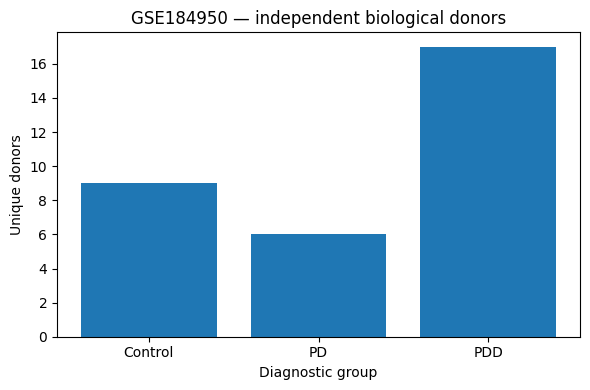

In [19]:
# 18. Figure — unique donors by diagnostic group
donor_counts_plot = (
    donor_level["disease"]
    .value_counts()
    .reindex(["Control", "PD", "PDD"])
    .dropna()
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(donor_counts_plot.index, donor_counts_plot.values)
ax.set_ylabel("Unique donors")
ax.set_xlabel("Diagnostic group")
ax.set_title("GSE184950 — independent biological donors")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE184950_unique_donors_by_disease.png", dpi=300, bbox_inches="tight")
plt.show()

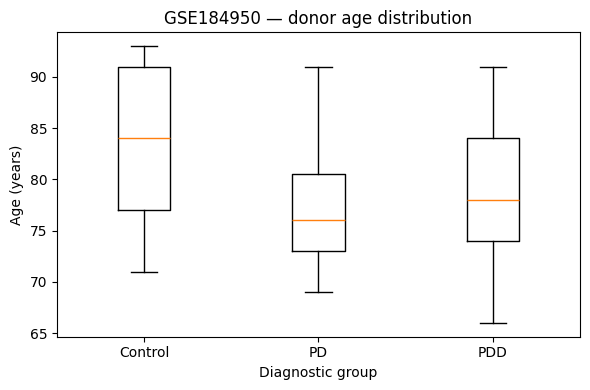

In [20]:
# 19. Figure — age distribution by disease at donor level
groups, labels = [], []
for group in ["Control", "PD", "PDD"]:
    vals = donor_level.loc[donor_level["disease"] == group, "age_numeric"].dropna().to_numpy()
    if len(vals):
        groups.append(vals)
        labels.append(group)

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(groups, tick_labels=labels)
ax.set_ylabel("Age (years)")
ax.set_xlabel("Diagnostic group")
ax.set_title("GSE184950 — donor age distribution")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE184950_age_by_disease.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation checkpoint — GSE184950

Notebook 01 stops at **donor/sample metadata** for GSE184950.

For Notebook 06 we will need the cell-level supplementary matrices (`matrix`, `barcodes`, `features/genes`, or equivalent 10x outputs). The inferential biological unit will remain the **donor**, not the nucleus. This motivates a donor-level pseudobulk workflow after cell-type annotation.

# Part C — Cross-dataset design audit

In [21]:
# 20. Study-design table
study_design = pd.DataFrame([
    {
        "dataset": "GSE136666",
        "technology": "Bulk RNA-seq",
        "tissue": "Substantia nigra + Putamen",
        "primary_role": "Discovery",
        "primary_contrast": "SN Parkinson vs Control",
        "biological_unit": "Independent pooled library",
        "expression_matrix_available_in_notebook01": True,
    },
    {
        "dataset": "GSE184950",
        "technology": "snRNA-seq",
        "tissue": "Substantia nigra",
        "primary_role": "Independent cell-resolution validation",
        "primary_contrast": "PD vs Control; PDD secondary",
        "biological_unit": "Donor",
        "expression_matrix_available_in_notebook01": False,
    },
])
display(study_design)

,dataset,technology,tissue,primary_role,primary_contrast,biological_unit,expression_matrix_available_in_notebook01
0,GSE136666,Bulk RNA-seq,Substantia nigra + Putamen,Discovery,SN Parkinson vs Control,Independent pooled library,True
1,GSE184950,snRNA-seq,Substantia nigra,Independent cell-resolution validation,PD vs Control; PDD secondary,Donor,False


In [22]:
# 21. Export validated inputs for later notebooks
meta136.to_csv(EXPORT_DIR / "GSE136666_metadata_clean.csv", index=False)
meta184.to_csv(EXPORT_DIR / "GSE184950_metadata_clean.csv", index=False)
donor_level.to_csv(EXPORT_DIR / "GSE184950_donor_level_metadata.csv", index=False)

bulk_qc.to_csv(RESULTS_DIR / "GSE136666_bulk_QC.csv", index=False)
distribution_qc.to_csv(RESULTS_DIR / "GSE136666_distribution_QC.csv", index=False)
filter_audit.to_csv(RESULTS_DIR / "GSE136666_filter_audit.csv", index=False)
filter_flags.to_csv(EXPORT_DIR / "GSE136666_candidate_filter_flags.csv", index=False)
duplicate_donors.to_csv(RESULTS_DIR / "GSE184950_repeated_donor_rows.csv", index=False)
covariate_qc.to_csv(RESULTS_DIR / "GSE184950_covariate_QC.csv", index=False)
study_design.to_csv(RESULTS_DIR / "study_design.csv", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "GSE136666": {
        **bulk_integrity,
        "metadata_rows": int(len(meta136)),
        "primary_tissue": "Substantia_nigra",
        "next_notebook": "02_bulk_preprocessing.ipynb",
    },
    "GSE184950": {
        **donor_summary,
        "diagnostic_groups": sorted(meta184["disease"].dropna().unique().tolist()),
        "next_single_cell_notebook": "06_single_nucleus_preprocessing.ipynb",
    },
}

with open(EXPORT_DIR / "notebook01_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("Saved outputs:")
for p in sorted(EXPORT_DIR.glob("*")):
    print("  ", p)
for p in sorted(RESULTS_DIR.glob("*")):
    print("  ", p)

Saved outputs:
   /mnt/data/data/processed/notebook01/GSE136666_candidate_filter_flags.csv
   /mnt/data/data/processed/notebook01/GSE136666_metadata_clean.csv
   /mnt/data/data/processed/notebook01/GSE184950_donor_level_metadata.csv
   /mnt/data/data/processed/notebook01/GSE184950_metadata_clean.csv
   /mnt/data/data/processed/notebook01/notebook01_manifest.json
   /mnt/data/results/QC/GSE136666_bulk_QC.csv
   /mnt/data/results/QC/GSE136666_distribution_QC.csv
   /mnt/data/results/QC/GSE136666_filter_audit.csv
   /mnt/data/results/QC/GSE184950_covariate_QC.csv
   /mnt/data/results/QC/GSE184950_repeated_donor_rows.csv
   /mnt/data/results/QC/study_design.csv


In [23]:
# 22. Final automated checkpoint
checks = {
    "GSE136666 has 16 samples": len(meta136) == 16,
    "GSE136666 count/metadata IDs match": set(sample_columns) == set(meta136["geo_accession"]),
    "GSE136666 raw counts are integer-valued": bulk_integrity["all_counts_integer_valued"],
    "GSE136666 raw counts have no missing values": bulk_integrity["count_missing_values"] == 0,
    "GSE184950 has disease labels": meta184["disease"].notna().all(),
    "GSE184950 donor IDs recovered": meta184[donor_col].notna().all(),
    "GSE184950 donor duplication explicitly audited": donor_summary["unique_donors"] <= donor_summary["geo_sample_rows"],
}

checkpoint = pd.Series(checks, name="passed")
display(checkpoint)

if checkpoint.all():
    print("\n✓ Notebook 01 audit passed.")
    print("GSE136666 is ready for Notebook 02 bulk preprocessing.")
    print("GSE184950 metadata is ready; cell matrices are still required for Notebook 06.")
else:
    print("\n⚠ One or more checks failed. Review before continuing.")

GSE136666 has 16 samples                          True
GSE136666 count/metadata IDs match                True
GSE136666 raw counts are integer-valued           True
GSE136666 raw counts have no missing values       True
GSE184950 has disease labels                      True
GSE184950 donor IDs recovered                     True
GSE184950 donor duplication explicitly audited    True
Name: passed, dtype: bool


✓ Notebook 01 audit passed.
GSE136666 is ready for Notebook 02 bulk preprocessing.
GSE184950 metadata is ready; cell matrices are still required for Notebook 06.


# Outputs used downstream

### Notebook 02
- `GSE136666_metadata_clean.csv`
- original GSE136666 raw-count matrix
- `GSE136666_candidate_filter_flags.csv`
- GSE136666 QC tables

### Notebook 06
- `GSE184950_metadata_clean.csv`
- `GSE184950_donor_level_metadata.csv`
- **plus the cell-level GSE184950 expression matrices to be downloaded separately**

## What Notebook 02 will do
1. Restrict the primary analysis to substantia nigra.
2. Compare reasonable low-count filtering rules.
3. Implement DESeq2-style normalization in Python with PyDESeq2.
4. Generate normalized-expression QC, PCA and sample-distance analysis.
5. Compare candidate designs `~ disease` and `~ sex + disease` before differential-expression testing.